# Data Understanding and EDA on cleaned data 
## Notebook 2

#### Introduction
This Jupyter notebook delves into a comprehensive overview of exploratory data analysis (EDA) performed on a cleansed dataset. We will use various visualisations to better understand our data and choose features for the modelling phase.

#### Read before proceeding:

In this notebook I import custom functions that are contained on **utility_functions.py** inside the directory **custom_functions**. In this way, the notebook looks clean and is easy to understand while complex functions can be referenced if needed (from utility_functions.py).

#### Imports

In [1]:
import importlib
from custom_functions import utility_functions
importlib.reload(utility_functions)

## for data manipulation and analysis
import scipy.stats as stats
import numpy as np
import pandas as pd

# visualisation tools
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

# ML libraries
from sklearn.preprocessing import LabelEncoder

#### Importing cleansed dataset

In [2]:
df = pd.read_csv('data_clean/clean_dataset.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Age                       100000 non-null  float64
 4   Occupation                100000 non-null  object 
 5   Annual_Income             100000 non-null  float64
 6   Monthly_Inhand_Salary     100000 non-null  float64
 7   Num_Bank_Accounts         100000 non-null  float64
 8   Num_Credit_Card           100000 non-null  float64
 9   Interest_Rate             100000 non-null  float64
 10  Num_of_Loan               100000 non-null  float64
 11  Type_of_Loan              100000 non-null  object 
 12  Delay_from_due_date       100000 non-null  float64
 13  Num_of_Delayed_Payment    100000 non-null  fl

#### Deciding which data time screenshots to keep based on the month feature
Because this project is running on a local machine I want to reduce the dataset's dimensions to be able to apply more complex models later. I will keep the most current months (month 8 or 7 & 8) for every customer. I have 12500 distinct customers based on **Customer_ID**.

In [3]:
df.head(3)

,ID,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,24.785217,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,24.785217,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,24.785217,Low_spent_Medium_value_payments,331.209863,Good


In [4]:
df.query('Month == 8').shape

(12500, 26)

In [5]:
df.query('Month == 8 or Month == 7').shape

(25000, 26)

In the code below, two bar charts are created side by side for comparing the distribution of 'Credit_Score' in different conditions (different months and combination of months). In other words, the first chart will show the distribution of 'Credit_Score' for rows where 'Month' equals 8, and the second chart for rows where 'Month' equals 7 or 8.

In [6]:
fig, axs = plt.subplots(1,2, figsize=(11,6))
df8 = df.query('Month == 8')
df78= df.query('Month == 8 or Month == 7')


# Plot for 'data' DataFrame
(df8['Credit_Score'].value_counts(normalize = True)*100).plot(kind='bar', ax=axs[0])
axs[0].set_title('Percentage of credit score categories \n(only  month == 8 included)')
axs[0].set_ylabel('Percentage')
axs[0].set_xlabel('Credit Score Category')

# Plot for 'data_reduced' DataFrame
(df78['Credit_Score'].value_counts(normalize = True)*100).plot(kind='bar', ax=axs[1])
axs[1].set_title('Percentage of credit score categories \n(only month == 8 OR month == 7 included)')
axs[1].set_ylabel('Percentage')
axs[1].set_xlabel('Credit Score Category')

#plt.tight_layout()
plt.show()

<Figure size 1100x600 with 2 Axes>

To better enhance the above visualisations I provide the count of credit score categories for the same conditions:

In [7]:
#printing the counts:
print('Count of credit score categories (only month == 8 included):')
print((df8['Credit_Score'].value_counts(normalize = False)).reset_index())
print('\n\n')
print('Count of credit score categories (only month == 8 OR month == 7 included):')
print((df78['Credit_Score'].value_counts(normalize = False)).reset_index())

Count of credit score categories (only month == 8 included):
  Credit_Score  count
0     Standard   6485
1         Poor   3602
2         Good   2413



Count of credit score categories (only month == 8 OR month == 7 included):
  Credit_Score  count
0     Standard  12960
1         Poor   7216
2         Good   4824


In [8]:
#printing the percentages:
print('Percentage of credit score categories (only for month == 8):')
print((df8['Credit_Score'].value_counts(normalize = True)*100).reset_index())
print('\n\n')
print('Percentage of credit score categories (month == 8 OR month == 7):')
print((df78['Credit_Score'].value_counts(normalize = True)*100).reset_index())

Percentage of credit score categories (only for month == 8):
  Credit_Score  proportion
0     Standard      51.880
1         Poor      28.816
2         Good      19.304



Percentage of credit score categories (month == 8 OR month == 7):
  Credit_Score  proportion
0     Standard      51.840
1         Poor      28.864
2         Good      19.296


In a similar way I will try a different combination (month == 1 OR 8):

In [9]:
df18 = df.query('Month == 8 or Month == 1')

#printing the counts:
print('Count of credit score categories (only month == 8 included):')
print((df8['Credit_Score'].value_counts(normalize = False)).reset_index())
print('\n\n')
print('Count of credit score categories (only month == 8 OR month == 1 included):')
print((df18['Credit_Score'].value_counts(normalize = False)).reset_index())

print('\n\n------------\n\n')

#printing the percentages:
print('Percentage of credit score categories (only for month == 8):')
print((df8['Credit_Score'].value_counts(normalize = True)*100).reset_index())
print('\n\n')
print('Percentage of credit score categories (month == 8 OR month == 1 included):')
print((df18['Credit_Score'].value_counts(normalize = True)*100).reset_index())

Count of credit score categories (only month == 8 included):
  Credit_Score  count
0     Standard   6485
1         Poor   3602
2         Good   2413



Count of credit score categories (only month == 8 OR month == 1 included):
  Credit_Score  count
0     Standard  13428
1         Poor   7184
2         Good   4388


------------


Percentage of credit score categories (only for month == 8):
  Credit_Score  proportion
0     Standard      51.880
1         Poor      28.816
2         Good      19.304



Percentage of credit score categories (month == 8 OR month == 1 included):
  Credit_Score  proportion
0     Standard      53.712
1         Poor      28.736
2         Good      17.552


**I decided to  keep the subset with most current month (month == 8) per Customer_ID. There are no big differences on the count of classes of the target variable between the above subsets**.

Note: Normally I should check all the numerical feature's distributions, categorical features' classes counts and percentages of the above subsets. For reasons of simplicity, I make the assumption that there are no significant changes of features' characteristics when choosing my final subset.

**Assigning subset to data Dataframe**:

In [10]:
data = df.query('Month == 8')
data.shape

(12500, 26)

Which features should I drop first (as they will be no useful in modelling phase)?

In [11]:
df.columns.values

array(['ID', 'Customer_ID', 'Month', 'Age', 'Occupation', 'Annual_Income',
       'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
       'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment',
       'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix',
       'Outstanding_Debt', 'Credit_Utilization_Ratio',
       'Credit_History_Age', 'Payment_of_Min_Amount',
       'Total_EMI_per_month', 'Amount_invested_monthly',
       'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score'],
      dtype=object)

Features **Month** and **ID** (now ID is actually the same as Customer_ID which is unique per observation) are obsolete and will be dropped:

In [12]:
# dropping features and resetting indexL
data = data.drop(['ID','Month'], axis = 1, inplace = False).reset_index().drop(['index'], axis = 1, inplace = False)
data.shape

(12500, 24)

In [13]:
data.info()
#pd.DataFrame(data.columns.values)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               12500 non-null  int64  
 1   Age                       12500 non-null  float64
 2   Occupation                12500 non-null  object 
 3   Annual_Income             12500 non-null  float64
 4   Monthly_Inhand_Salary     12500 non-null  float64
 5   Num_Bank_Accounts         12500 non-null  float64
 6   Num_Credit_Card           12500 non-null  float64
 7   Interest_Rate             12500 non-null  float64
 8   Num_of_Loan               12500 non-null  float64
 9   Type_of_Loan              12500 non-null  object 
 10  Delay_from_due_date       12500 non-null  float64
 11  Num_of_Delayed_Payment    12500 non-null  float64
 12  Changed_Credit_Limit      12500 non-null  float64
 13  Num_Credit_Inquiries      12500 non-null  float64
 14  Credit

##### Based on experts' opinion:
During this project I interviewed an expert professional. 
In Credit Scoring, the most used features on industry models are:
- Annual_Income
- Monthly_Inhand_Salary
- Outstanding_Debt
- Payment_Behaviour
- Credit_Mix
- Delay_from_due_date
- Num_of_Delayed_Payment
- Credit_Utilization_Ratio

In other words I will analyse the above features first and if I deem it necessary then I will add more variables.

In [14]:
# just viewing my table
data[['Customer_ID','Annual_Income','Monthly_Inhand_Salary','Outstanding_Debt','Payment_Behaviour','Delay_from_due_date','Num_of_Delayed_Payment','Credit_Utilization_Ratio','Credit_Score']].head()

,Customer_ID,Annual_Income,Monthly_Inhand_Salary,Outstanding_Debt,Payment_Behaviour,Delay_from_due_date,Num_of_Delayed_Payment,Credit_Utilization_Ratio,Credit_Score
0,3392,19114.12,1824.843333,809.98,High_spent_Medium_value_payments,3.0,6.0,23.933795,Standard
1,8625,34847.84,3037.986667,605.03,Low_spent_Small_value_payments,3.0,4.0,32.933856,Good
2,11708,143162.64,12187.220000,1303.01,High_spent_Small_value_payments,8.0,6.0,26.519815,Standard
3,47249,30689.89,2612.490833,632.46,High_spent_Small_value_payments,4.0,9.0,27.332515,Standard
4,7387,35547.71,2853.309167,943.86,High_spent_Small_value_payments,1.0,15.0,25.862922,Standard


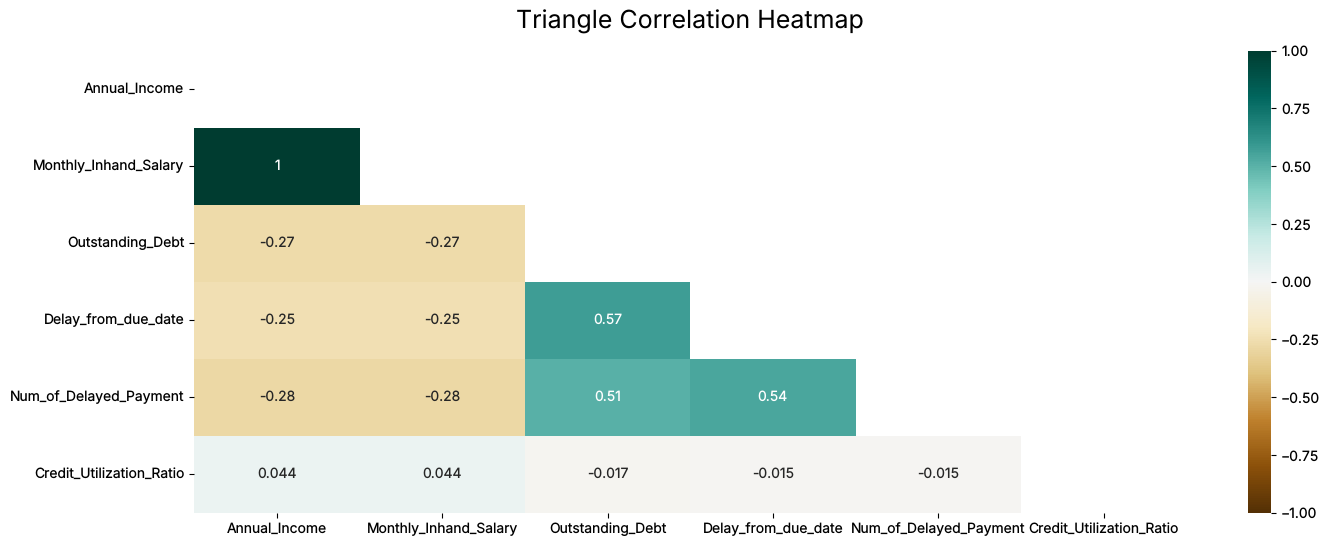

In [15]:
from custom_functions.utility_functions import plot_triangular_heatmap
temp = data[['Annual_Income',
             'Monthly_Inhand_Salary',
             'Outstanding_Debt',
             'Delay_from_due_date',
             'Num_of_Delayed_Payment',
             'Credit_Utilization_Ratio']]

plot_triangular_heatmap(temp)


The **Annual Income** is **strongly correlated** with the **Monthly Inhand Salary**. As a result I will **drop the Monthly Inhand Salary**. I should also check the correlation between all numeric variables:

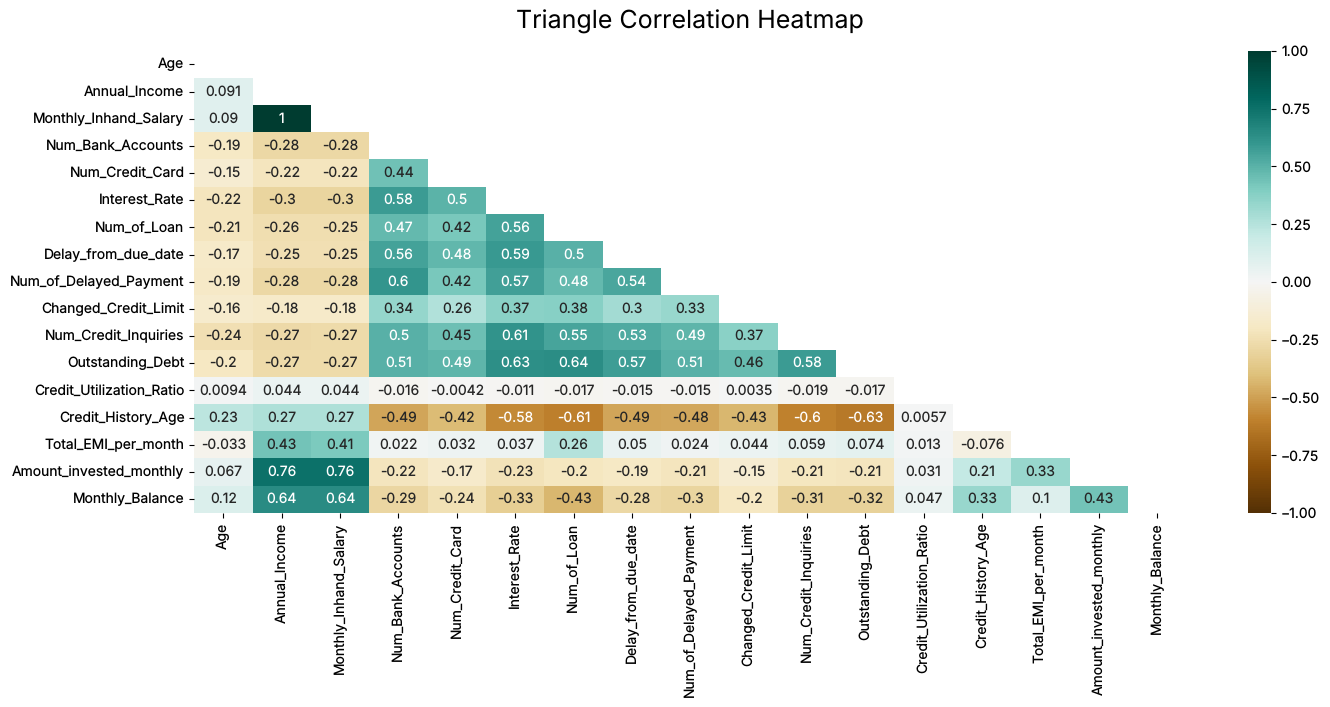

In [16]:
# plotting the corellations between all numerical variables (excluding Customer_ID)
plot_triangular_heatmap(data.select_dtypes(include = ['int64','float64'][1:]))

Based on the above graph I will also include the variable **Total_EMI_per_month** and **Age**. 

**The general idea of choosing the features is to include a subset of features that do not show a correlation of 0.6 and above with other included features on the subset.**

Now, I will create **box-plots** and **violin-plots** for every **numerical feature** per **Credit Score class**.

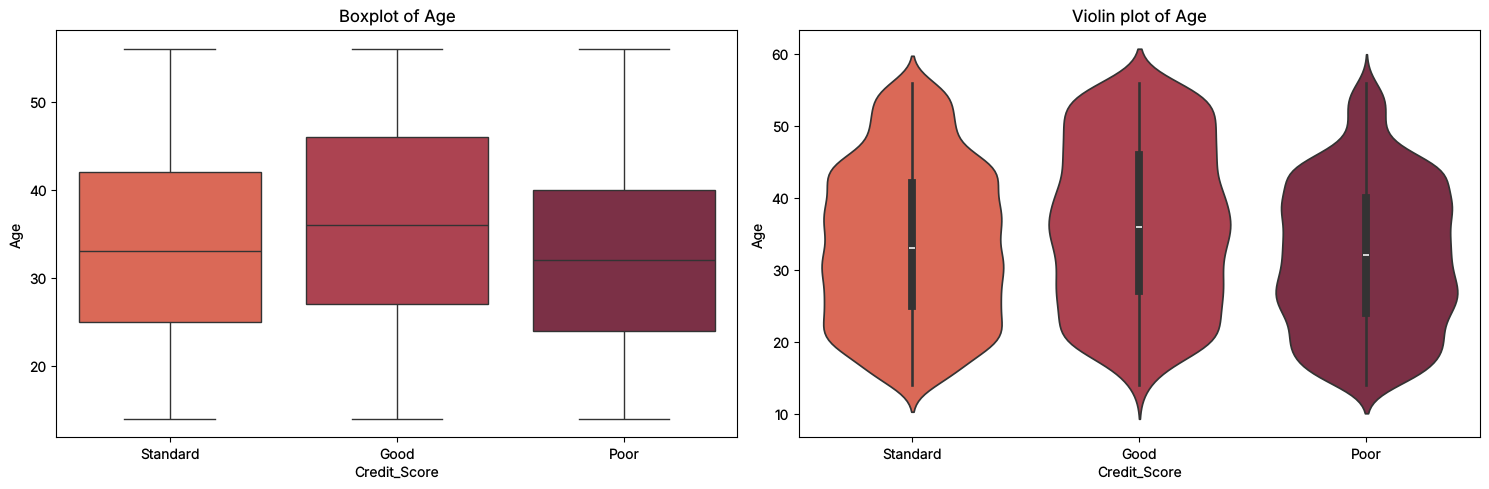

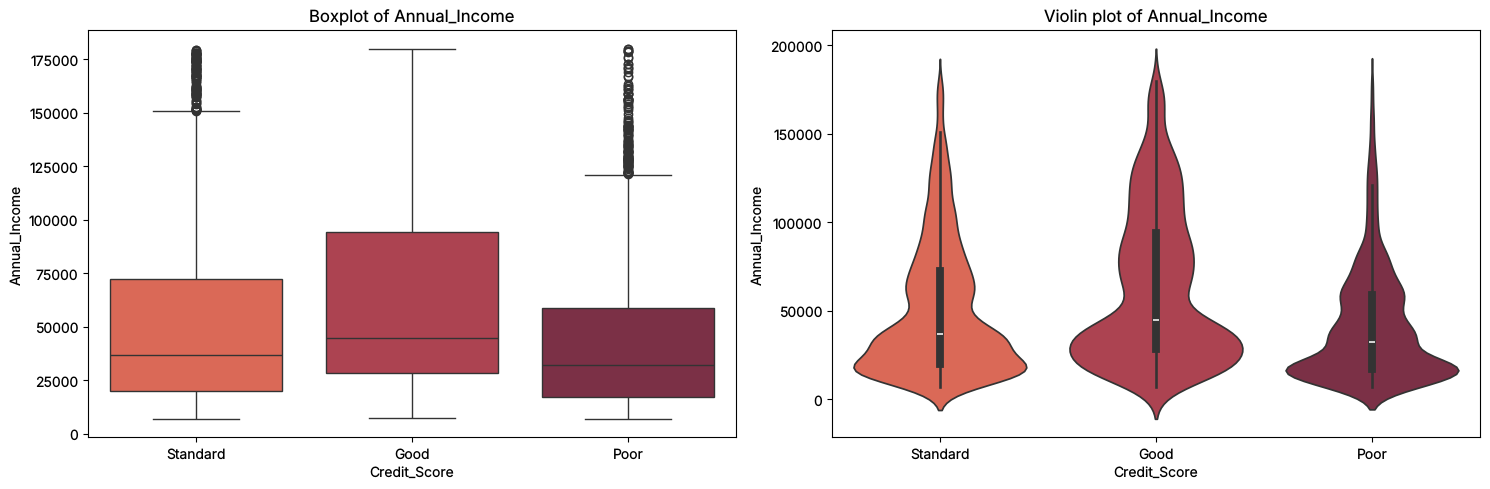

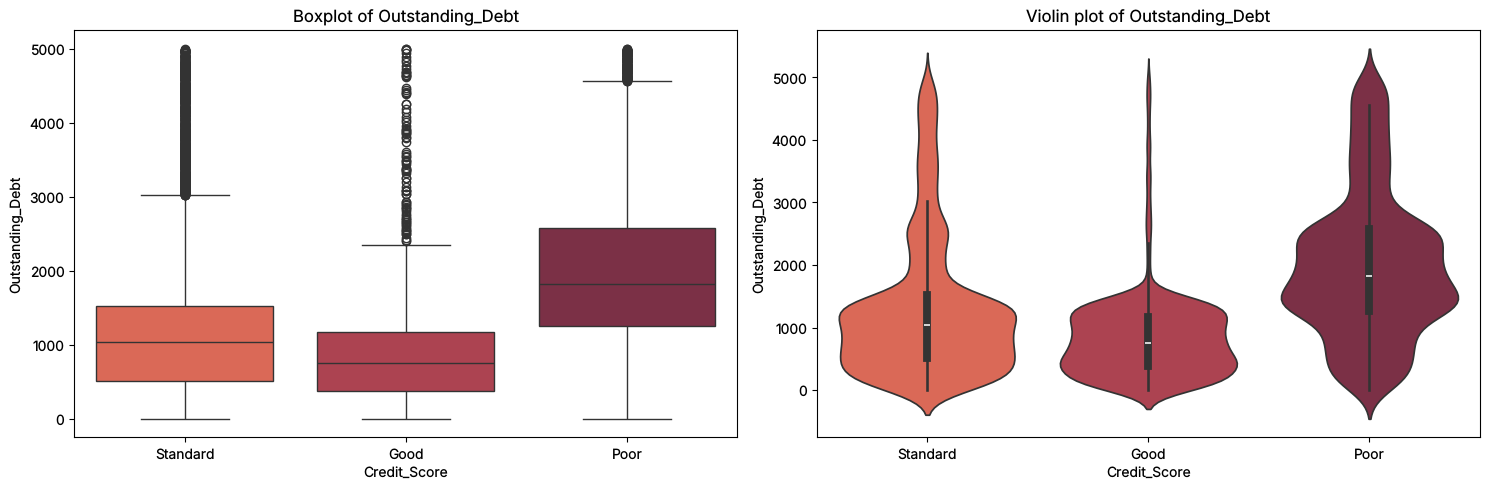

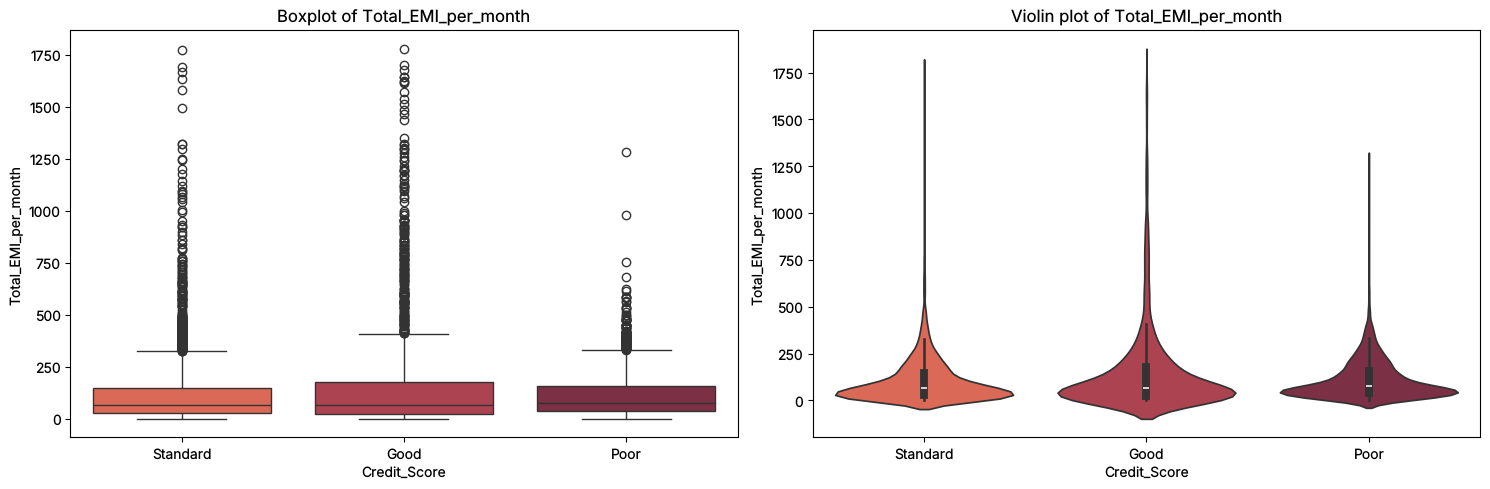

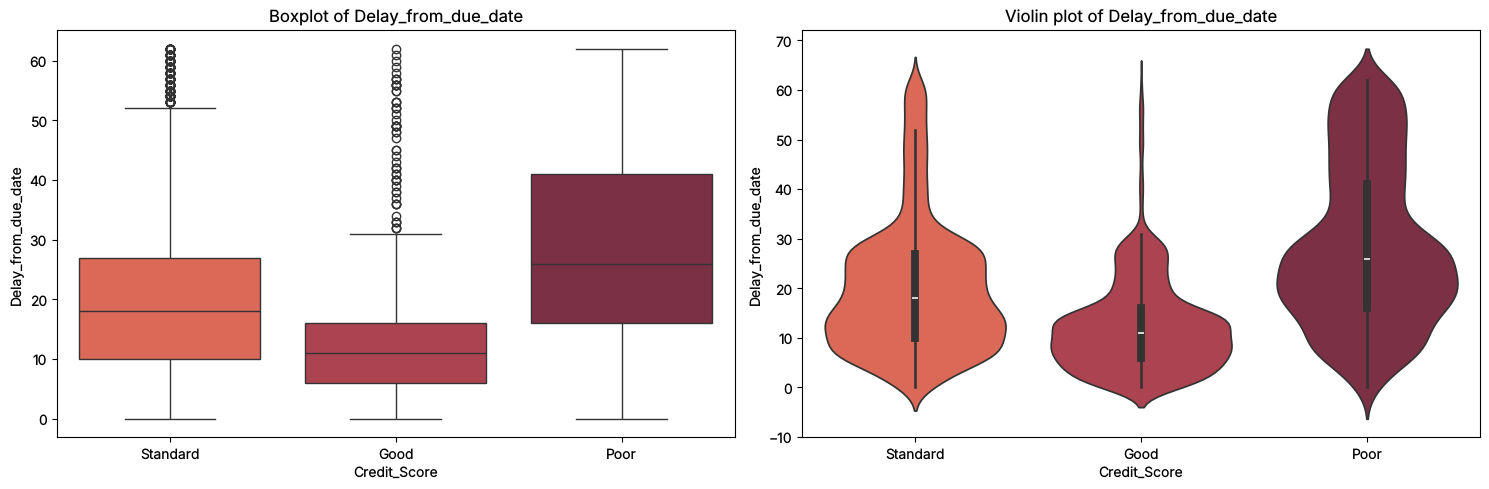

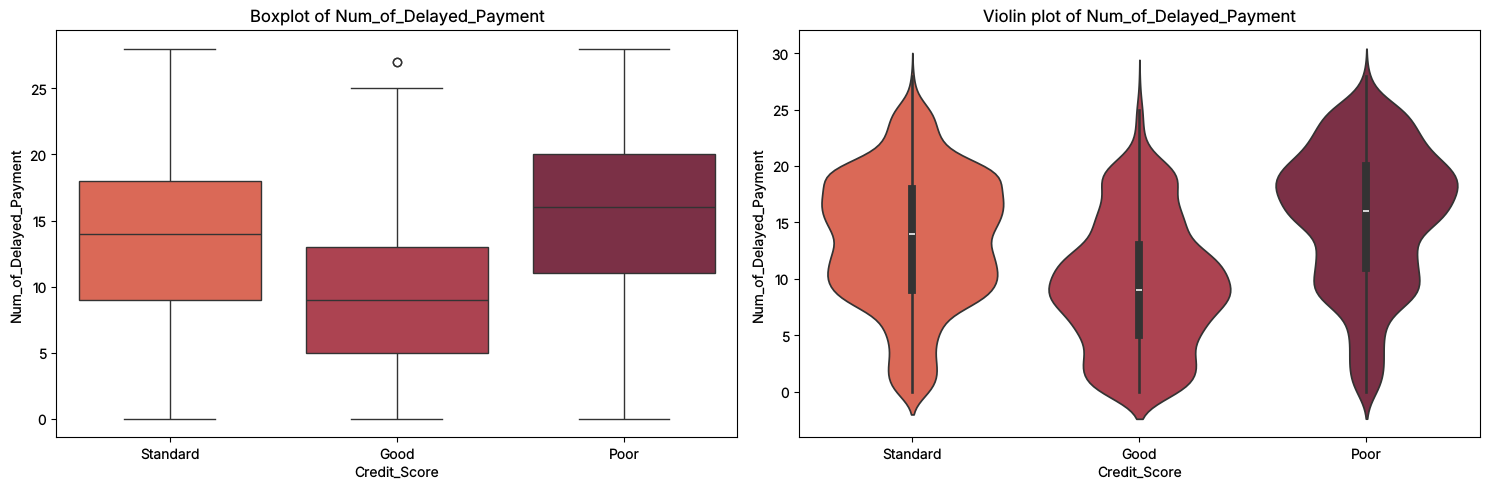

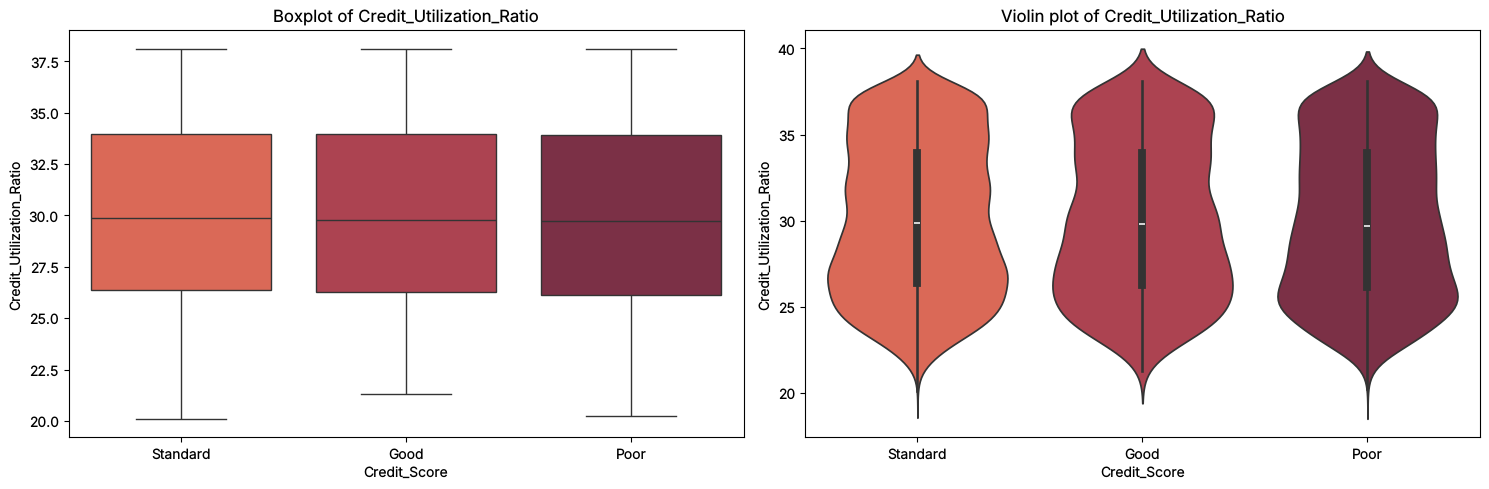

In [17]:
from custom_functions.utility_functions import create_plots_box_violin

temp = data[['Age',
             'Annual_Income',
             'Outstanding_Debt',
             'Total_EMI_per_month',
             'Delay_from_due_date',
             'Num_of_Delayed_Payment',
             'Credit_Utilization_Ratio',
             'Credit_Score']]

#
create_plots_box_violin(temp)

Based on the above plots I should drop **Credit_Utilization_Ratio** as its values and distributions does not change per Credit Score class. Also, I will consider later if **Total EMI per month** should be included in the final features.

Note: The EMI (Equated Monthly Installment) is the fixed amount you pay each month against a loan, which includes both the principal amount and the interest.

In [18]:
# dropping the Credit_Utilization_Ratio and checking the columns of temp
temp.drop('Credit_Utilization_Ratio',axis=1)
pd.DataFrame(temp.columns.values)

,0
0,Age
1,Annual_Income
2,Outstanding_Debt
3,Total_EMI_per_month
4,Delay_from_due_date
5,Num_of_Delayed_Payment
6,Credit_Utilization_Ratio
7,Credit_Score


I concluded that my numerical values will be the features as shown above. Now I should check how to handle the categorical features:
- Occupation
- Type_of_Loan
- Credit_Mix
- Payment_of_Min_Amount
- Payment_Behaviour

In [19]:
data.select_dtypes(include='object').head(3)

,Occupation,Type_of_Loan,Credit_Mix,Payment_of_Min_Amount,Payment_Behaviour,Credit_Score
0,Scientist,"auto loan,credit-builder loan,personal loan,ho...",Good,No,High_spent_Medium_value_payments,Standard
1,Teacher,credit-builder loan,Good,No,Low_spent_Small_value_payments,Good
2,Engineer,"auto loan,auto loan,not specified",Good,No,High_spent_Small_value_payments,Standard


As demonstrated previously, I will keep the **Payment_Behaviour** as it is broadly used on Credit Score models (experts' opinion). 

Also, **Credit_Mix** is a strong feature. Credit Mix refers to the various types of loan accounts that constitute customers' credit report. These accounts can include:

- Revolving Loans: These are accounts where customers can borrow repeatedly up to a certain credit limit. Examples include credit cards.
- Installment Loans: These involve fixed payments over a specified period. Examples include student loans, automobile loans, and mortgages.

The credit mix plays a role in determining the FICO credit score of a customer, accounting for 10% of it. Having a diverse credit mix provides creditors with more information about customer's ability to manage different types of credit.


In [20]:
print(data['Payment_Behaviour'].unique())

['High_spent_Medium_value_payments' 'Low_spent_Small_value_payments'
 'High_spent_Small_value_payments' 'Low_spent_Large_value_payments'
 'Low_spent_Medium_value_payments' 'High_spent_Large_value_payments']


There are 6 unique categories as shown above.

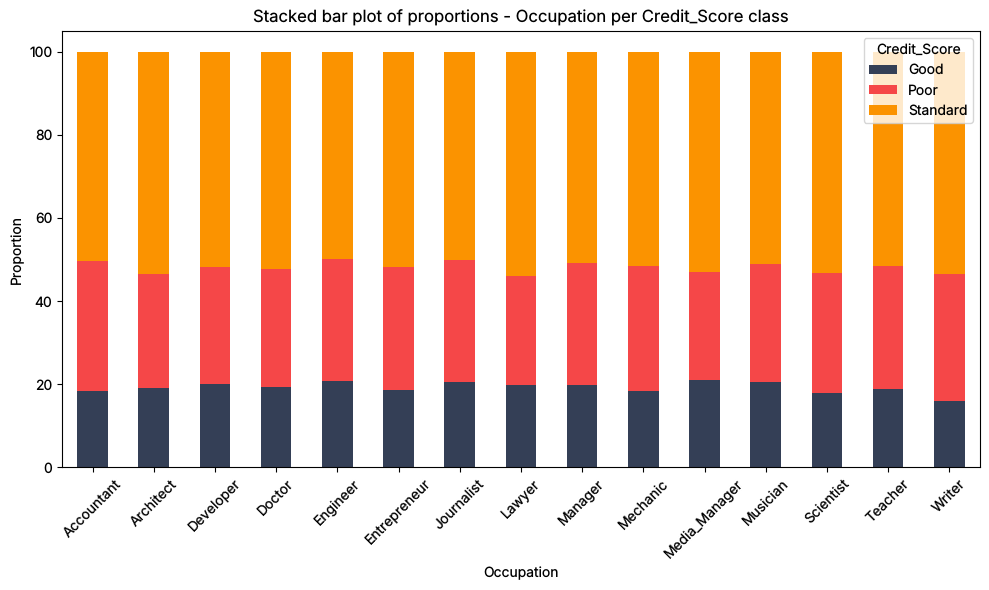

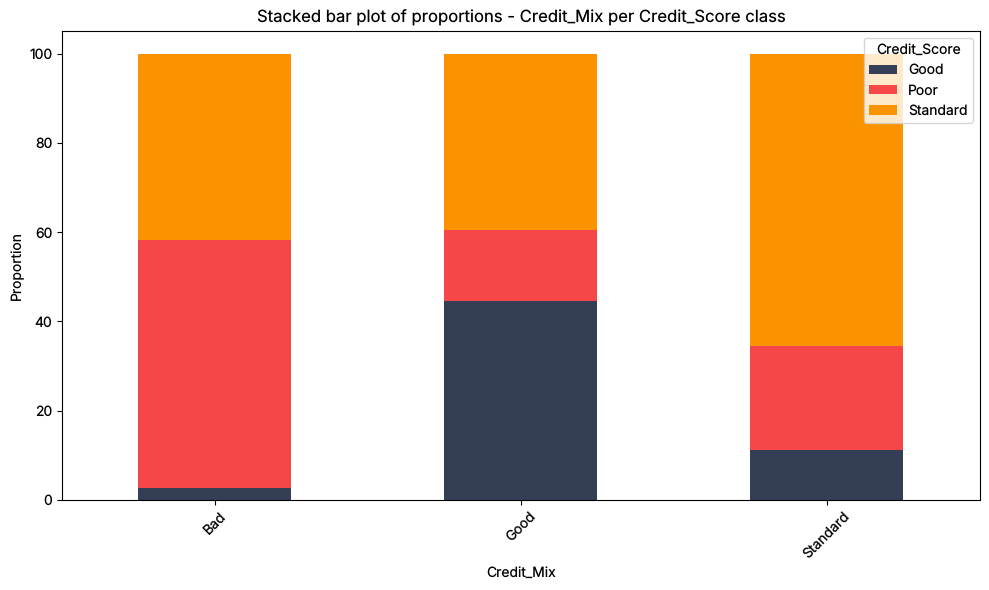

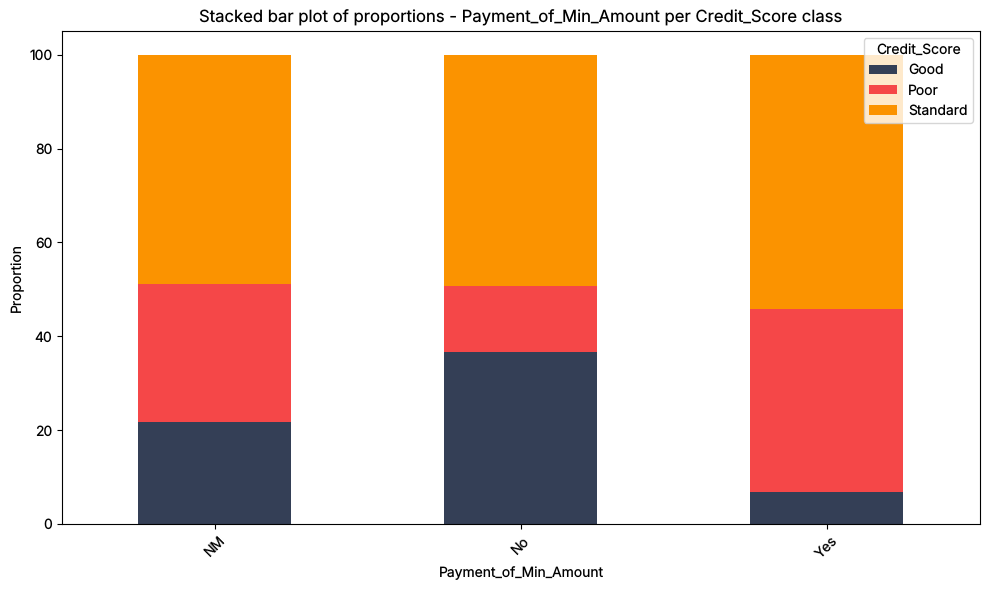

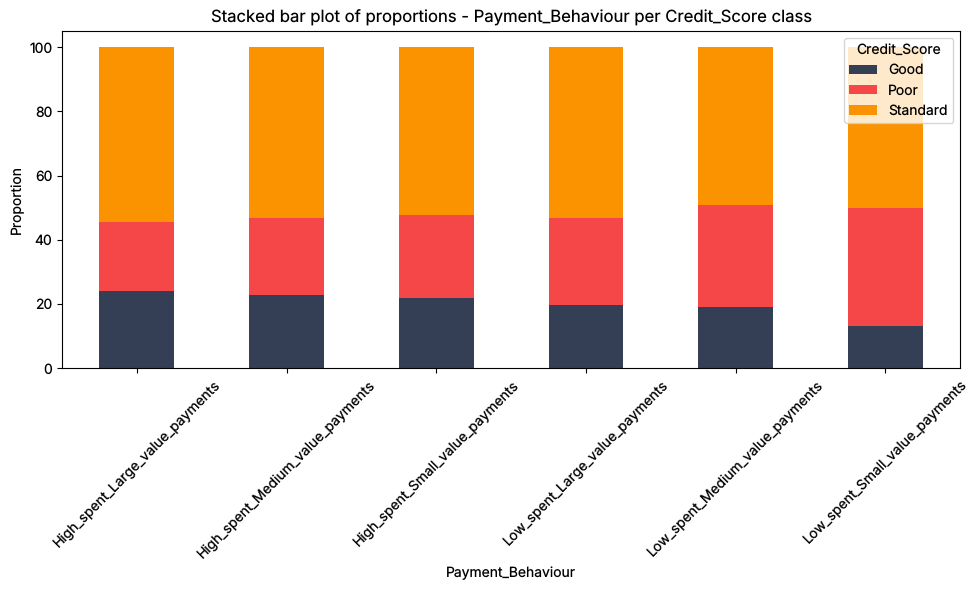

In [21]:
from custom_functions.utility_functions import plot_categorical_stacked

# Usage (for proportions)
plot_categorical_stacked(data, target = 'Credit_Score',
                         excluded_feats=['Type_of_Loan'],
                         percentage= True,
                         color_map = ['#343F56','#F54748','#FB9300'])

# Usage (for counts)
#plot_categorical_stacked(df)

According to the above plots:
- I will keep the following categorical features: **Payment_Behaviour, Credit_Mix, Payment_Min_Amount**.
- **Occupation** contains 15 unique values. In other words, it is a high cardinality feature and I should consider if it will be included into the modelling phase later.
- **Occupation** and **Payment_Behaviour** do not show significant different proportions of classes per their categories. In other words, if these features do not add value as inputs to ML models, they will be dropped. Until then, I will keep them in my dataset.

Furthermore, I will not include the **Type_of_Loan**. Its high cardinality makes it difficult to preprocess it into a suitable model input in my local machine.

### Concluding:
I decided to keep the latest time-screenshot of the dataset. This means that I have 12500 observations (1 per customer).

Furthermore, as a result of the above EDA analysis I decided to conclude the following features:
- Age
- Annual_Income
- Outstanding_Debt
- Total_EMI_per_month
- Delay_from_due_date
- Num_of_Delayed_Payment
- Credit_Utilization_Ratio
- Payment_Behaviour
- Credit_Mix
- Payment_of_Min_Amount

And for later use the Occupation variable.

Below the subset is exported to a csv:


In [22]:
included_features = \
['Customer_ID',
 'Age',
 'Annual_Income',
 'Outstanding_Debt',
 'Total_EMI_per_month',
 'Delay_from_due_date',
 'Num_of_Delayed_Payment',
 'Credit_Utilization_Ratio',
 'Payment_Behaviour',
 'Credit_Mix',
 'Payment_of_Min_Amount',
 'Occupation',
 'Credit_Score']

print('Count of observations of the final dataset: '+ str(data[included_features].shape[0])+'\n')
print('Number of total variables of the final dataset: '+ str(data[included_features].shape[1]))

Count of observations of the final dataset: 12500

Number of total variables of the final dataset: 13


Exporting the subset as demonstrated above:

In [23]:
data[included_features].to_csv("data_clean/for_models_dataset.csv", index=False)

**Important Note**: During the modelling phase I will probably increase the features and the observations depending on the needs of the models' performance.

In [24]:
print('Notebook runs without errors - End of Notebook 2')

Notebook runs without errors - End of Notebook 2
